# Hypothese 1: Lohnt sich ein Hauskauf im Winter?
EDA King County House Sales · Kunde: Thomas Hansen (5 Kinder, wenig Budget, braucht ein großes Haus)

**Hypothese:** Häuser mit mindestens 4 Schlafzimmern sind im Winter (November bis Februar) im Median mindestens 5 % günstiger als im Rest des Jahres.

**Gliederung**
1. Daten
2. Vorbereitung
3. Daten erkunden
4. Zusammenhänge
5. Hypothese prüfen
6. Folgefrage: Jahreszeit oder Lage?
7. Preis-Jahresuhr
8. Fazit

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from scipy import stats
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["text.parse_math"] = False  # "$" ist hier Währung, keine Formel
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
Path("output").mkdir(exist_ok=True)


# Zahlen im deutschen Format ausgeben (1.234,5)
def de(zahl, stellen=0):
    return f"{zahl:,.{stellen}f}".replace(",", "X").replace(".", ",").replace("X", ".")


# p-Werte in wissenschaftlicher Schreibweise mit Komma (z. B. 2,1e-06)
def p_de(p):
    return f"{p:.1e}".replace(".", ",")


# Kasten mit Kennzahlen direkt ins Diagramm schreiben
def kennzahlen(ax, text, x=0.98, y=0.97, ha="right", va="top"):
    ax.text(x, y, text, transform=ax.transAxes, ha=ha, va=va, fontsize=10,
            bbox=dict(boxstyle="round", facecolor="white", edgecolor="gray", alpha=0.9))


MONATE = ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"]

---
## 1. Daten
Wir arbeiten mit dem bereinigten Datensatz aus `04_eda_data_cleaning` (Hausverkäufe in King County, Washington).

In [2]:
# Daten wurden in 03_fetching_the_data_eda per SQL geholt und in 04_eda_data_cleaning bereinigt
df = pd.read_csv("data/eda_tk_cleaned.csv", parse_dates=["date"])
print("Zeilen, Spalten:", df.shape)
print("Zeitraum:", df["date"].min().date(), "bis", df["date"].max().date())
df.head()

Zeilen, Spalten: (21597, 26)
Zeitraum: 2014-05-02 bis 2015-05-27


,sale_id,house_id,date,price,bedrooms,bathrooms,qm_living,qm_lot,floors,waterfront,...,yr_renovated,zipcode,lat,long,qm_living15,qm_lot15,yr_renovated_unbekannt,keller_typ,preis_pro_qm_wohnflaeche,preis_pro_qm_grundstueck
0,1,7129300520,2014-10-13,"221,900.00",3,1.00,109.63,524.90,1.00,0,...,0,98178,47.51,-122.26,124.49,524.90,False,Kein Keller (0 qm),"2,024.08",422.75
1,2,6414100192,2014-12-09,"538,000.00",3,2.25,238.76,672.80,2.00,0,...,1991,98125,47.72,-122.32,157.01,709.69,False,Nutzbarer Keller (>= 5 qm),"2,253.31",799.64
2,3,5631500400,2015-02-25,"180,000.00",2,1.00,71.54,929.03,1.00,0,...,0,98028,47.74,-122.23,252.70,748.98,True,Kein Keller (0 qm),"2,516.07",193.75
3,4,2487200875,2014-12-09,"604,000.00",4,3.00,182.09,464.52,1.00,0,...,0,98136,47.52,-122.39,126.35,464.52,False,Nutzbarer Keller (>= 5 qm),"3,317.04","1,300.27"
4,5,1954400510,2015-02-18,"510,000.00",3,2.00,156.08,750.66,1.00,0,...,0,98074,47.62,-122.05,167.23,697.05,False,Kein Keller (0 qm),"3,267.56",679.40


In [3]:
# Für diese Hypothese brauchen wir nur wenige Spalten
spalten = ["date", "price", "bedrooms", "qm_living", "grade", "zipcode"]
print(df[spalten].dtypes, "\n")
print("Fehlende Werte je Spalte:\n", df[spalten].isna().sum())
df[spalten].describe()

date         datetime64[us]
price               float64
bedrooms              int64
qm_living           float64
grade                 int64
zipcode               int64
dtype: object 

Fehlende Werte je Spalte:
 date         0
price        0
bedrooms     0
qm_living    0
grade        0
zipcode      0
dtype: int64


,date,price,bedrooms,qm_living,grade,zipcode
count,21597,"21,597.00","21,597.00","21,597.00","21,597.00","21,597.00"
mean,2014-10-29 04:20:38.171968,"540,296.57",3.37,193.27,7.66,"98,077.95"
min,2014-05-02 00:00:00,"78,000.00",1.00,34.37,3.00,"98,001.00"
25%,2014-07-22 00:00:00,"322,000.00",3.00,132.85,7.00,"98,033.00"
50%,2014-10-16 00:00:00,"450,000.00",3.00,177.44,7.00,"98,065.00"
75%,2015-02-17 00:00:00,"645,000.00",4.00,236.90,8.00,"98,118.00"
max,2015-05-27 00:00:00,"7,700,000.00",11.00,"1,257.91",13.00,"98,199.00"
std,NaN,"367,368.14",0.90,85.29,1.17,53.51


**Was finden wir vor?**
- 21.597 Verkäufe mit 26 Spalten, verkauft zwischen 02.05.2014 und 27.05.2015. Das sind 13 Monate, also haben wir **nur einen einzigen Winter** (2014/15) in den Daten.
- Wichtig für uns:
  - `date` = Verkaufsdatum → daraus machen wir Monat und Jahreszeit
  - `price` = Verkaufspreis in $ (stetig)
  - `bedrooms` = Anzahl Schlafzimmer (diskret) → damit filtern wir die großen Häuser
  - `qm_living`, `grade`, `zipcode` brauchen wir später, um Größe, Bauqualität und Lage zu prüfen
- Es gibt **keine fehlenden Werte** in diesen Spalten.
- Der Preis ist **rechtsschief**: Mittelwert 540.297 $, Median 450.000 $. Ein paar sehr teure Häuser ziehen den Mittelwert nach oben. Deshalb vergleichen wir in diesem Notebook immer **Mediane**.

---
## 2. Vorbereitung
**Unsere Annahmen:**
- **Großes Haus** = mindestens 4 Schlafzimmer (Thomas braucht Platz für 7 Personen).
- **Winter** = November bis Februar. In diesen Monaten sind normalerweise weniger Käufer unterwegs.
- **5 %** ist unsere Grenze, ab der sich das Warten lohnt. Bei einem typischen Preis von ca. $575.000 sind das rund $29.000, also ungefähr die Kaufnebenkosten.

Dafür legen wir neue Spalten an (Monat, Winter ja/nein) und filtern auf die großen Häuser. Danach schauen wir uns die Ausreißer an.

Häuser mit mind. 4 Schlafzimmern: 8.816 von 21.597 Verkäufen (41%)


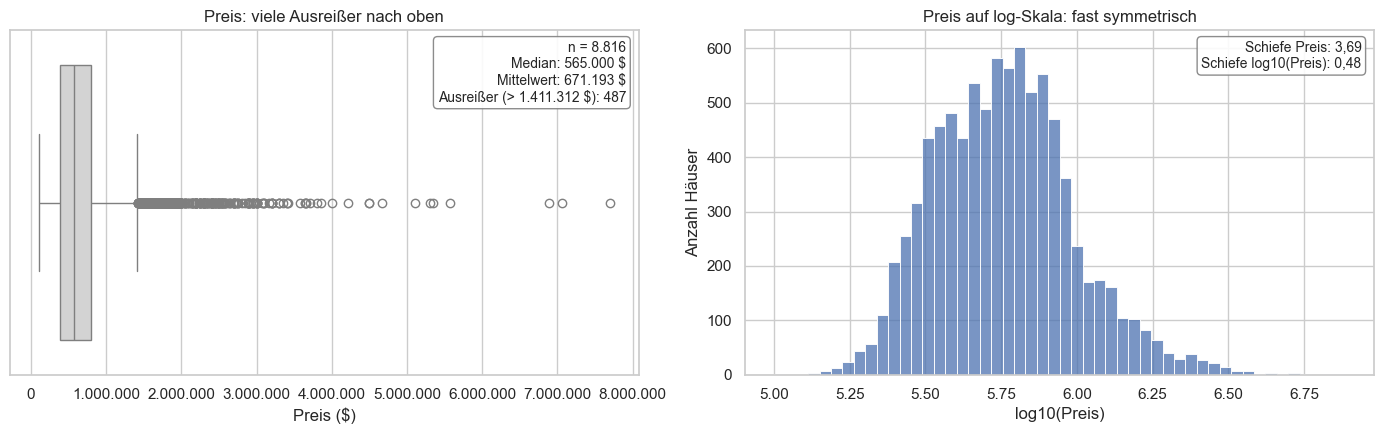

In [4]:
df["monat"] = df["date"].dt.month
df["winter"] = df["monat"].isin([11, 12, 1, 2])
df["saison"] = np.where(df["winter"], "Winter (Nov–Feb)", "Restjahr (Mär–Okt)")

gross = df[df["bedrooms"] >= 4].copy()
print(f"Häuser mit mind. 4 Schlafzimmern: {de(len(gross))} von {de(len(df))} Verkäufen ({len(gross) / len(df):.0%})")

# Ausreißer nach der 1,5-IQR-Regel zählen
q1, q3 = gross["price"].quantile([0.25, 0.75])
grenze = q3 + 1.5 * (q3 - q1)
n_ausreisser = (gross["price"] > grenze).sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(x=gross["price"], ax=axes[0], color="lightgray")
axes[0].set_title("Preis: viele Ausreißer nach oben")
axes[0].set_xlabel("Preis ($)")
axes[0].xaxis.set_major_formatter(lambda x, _: de(x))
kennzahlen(axes[0], f"n = {de(len(gross))}\nMedian: {de(gross['price'].median())} $\n"
                    f"Mittelwert: {de(gross['price'].mean())} $\n"
                    f"Ausreißer (> {de(grenze)} $): {de(n_ausreisser)}")

sns.histplot(np.log10(gross["price"]), bins=50, ax=axes[1])
axes[1].set_title("Preis auf log-Skala: fast symmetrisch")
axes[1].set_xlabel("log10(Preis)")
axes[1].set_ylabel("Anzahl Häuser")
kennzahlen(axes[1], f"Schiefe Preis: {de(gross['price'].skew(), 2)}\n"
                    f"Schiefe log10(Preis): {de(np.log10(gross['price']).skew(), 2)}")
plt.tight_layout()
plt.show()

**Kennzahlen:** n = 8.816 große Häuser (41 % aller Verkäufe) · Median 565.000 $ · Mittelwert 671.193 $ · 487 Ausreißer über 1.411.312 $ (1,5-IQR-Regel) · Schiefe 3,69 (log-Skala: 0,48)

**Entscheidung:** Der Boxplot zeigt viele teure Ausreißer. Das sind aber echte Verkäufe (große Villen) und keine Tippfehler. Weil wir Mediane vergleichen, stören sie das Ergebnis kaum. Wir **löschen deshalb nichts**. Auf der log-Skala ist der Preis fast symmetrisch verteilt, das hilft beim Lesen der Diagramme.

---
## 3. Daten erkunden
Bevor wir Preise vergleichen, schauen wir, wie viele große Häuser pro Monat verkauft werden und wie die Zielgruppe aufgebaut ist.

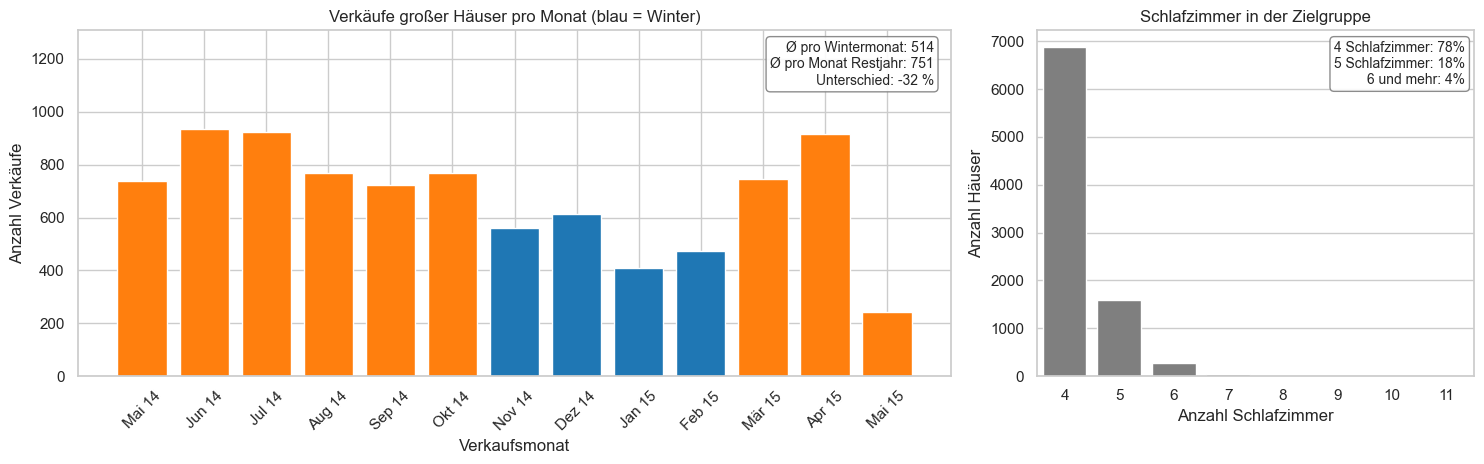

In [5]:
pro_periode = gross.groupby(gross["date"].dt.to_period("M")).size()
monat_namen = [f"{MONATE[p.month - 1]} {str(p.year)[2:]}" for p in pro_periode.index]
ist_winter = np.array([p.month in [11, 12, 1, 2] for p in pro_periode.index])
schnitt_winter = pro_periode[ist_winter].mean()
schnitt_rest = pro_periode[~ist_winter].mean()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [2, 1]})
axes[0].bar(monat_namen, pro_periode.values, color=np.where(ist_winter, "tab:blue", "tab:orange"))
axes[0].set_title("Verkäufe großer Häuser pro Monat (blau = Winter)")
axes[0].set_xlabel("Verkaufsmonat")
axes[0].set_ylabel("Anzahl Verkäufe")
axes[0].set_ylim(0, pro_periode.max() * 1.4)
axes[0].tick_params(axis="x", rotation=45)
kennzahlen(axes[0], f"Ø pro Wintermonat: {de(schnitt_winter)}\nØ pro Monat Restjahr: {de(schnitt_rest)}\n"
                    f"Unterschied: {de(100 * (schnitt_winter / schnitt_rest - 1))} %")

sns.countplot(x="bedrooms", data=gross, ax=axes[1], color="tab:gray")
axes[1].set_title("Schlafzimmer in der Zielgruppe")
axes[1].set_xlabel("Anzahl Schlafzimmer")
axes[1].set_ylabel("Anzahl Häuser")
kennzahlen(axes[1], f"4 Schlafzimmer: {(gross['bedrooms'] == 4).mean():.0%}\n"
                    f"5 Schlafzimmer: {(gross['bedrooms'] == 5).mean():.0%}\n"
                    f"6 und mehr: {(gross['bedrooms'] >= 6).mean():.0%}")
plt.tight_layout()
plt.show()

**Kennzahlen:** Ø 514 Verkäufe pro Wintermonat gegenüber Ø 751 im Restjahr (−32 %) · Zielgruppe: 78 % mit 4, 18 % mit 5 und 4 % mit 6 oder mehr Schlafzimmern

**Was bedeutet das?**
- Im Winter werden deutlich **weniger große Häuser verkauft** als im Frühling und Sommer. Weniger Nachfrage spricht erst einmal dafür, dass die Preise im Winter niedriger sein könnten.
- Die Zielgruppe besteht hauptsächlich aus Häusern mit 4 Schlafzimmern. Häuser mit 6 oder mehr Schlafzimmern sind selten.
- Mai 2014 und Mai 2015 sind nicht vollständig im Datensatz (Start am 02.05.2014, Ende am 27.05.2015).

---
## 4. Zusammenhänge
**Methode:** Mit einer Korrelationsmatrix sehen wir auf einen Blick, welche Merkmale mit dem Preis zusammenhängen. So können wir einschätzen, wie wichtig die Jahreszeit im Vergleich zu anderen Merkmalen ist (Werte von −1 bis +1, 0 = kein Zusammenhang).

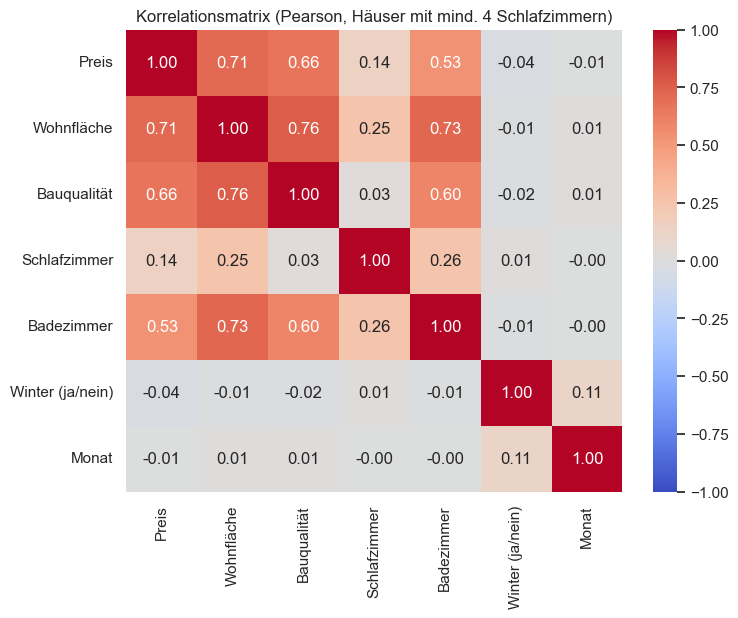

Korrelation mit dem Preis:
Wohnfläche          0.71
Bauqualität         0.66
Badezimmer          0.53
Schlafzimmer        0.14
Monat              -0.01
Winter (ja/nein)   -0.04
Name: Preis, dtype: float64


In [6]:
namen = {"price": "Preis", "qm_living": "Wohnfläche", "grade": "Bauqualität", "bedrooms": "Schlafzimmer",
         "bathrooms": "Badezimmer", "winter": "Winter (ja/nein)", "monat": "Monat"}
korr = gross[list(namen)].astype(float).corr().rename(index=namen, columns=namen)

plt.figure(figsize=(8, 6))
sns.heatmap(korr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Korrelationsmatrix (Pearson, Häuser mit mind. 4 Schlafzimmern)")
plt.show()

print("Korrelation mit dem Preis:")
print(korr["Preis"].drop("Preis").sort_values(ascending=False).round(2))

**Kennzahlen (Korrelation mit dem Preis):** Wohnfläche 0,71 · Bauqualität 0,66 · Badezimmer 0,53 · Schlafzimmer 0,14 · Monat −0,01 · Winter −0,04

**Was bedeutet das?** Den Preis bestimmen vor allem **Wohnfläche** und **Bauqualität**. Der Winter hängt nur sehr schwach mit dem Preis zusammen. Die Jahreszeit ist also im Vergleich ein kleiner Faktor. Klein heißt aber nicht null, deshalb schauen wir uns den Preis pro Monat genauer an.

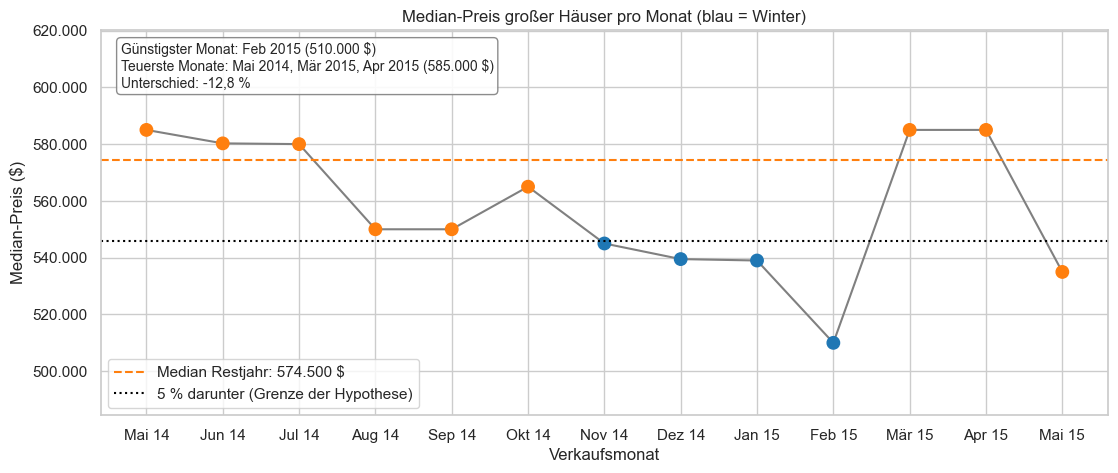

In [7]:
pro_monat = gross.groupby(gross["date"].dt.to_period("M"))["price"].median()
median_rest = gross.loc[~gross["winter"], "price"].median()
farben = ["tab:blue" if p.month in [11, 12, 1, 2] else "tab:orange" for p in pro_monat.index]
billig = pro_monat.idxmin()
teuer = [f"{MONATE[p.month - 1]} {p.year}" for p in pro_monat.index[pro_monat == pro_monat.max()]]

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(monat_namen, pro_monat.values, color="gray", zorder=1)
ax.scatter(monat_namen, pro_monat.values, c=farben, s=80, zorder=2)
ax.axhline(median_rest, ls="--", color="tab:orange", label=f"Median Restjahr: {de(median_rest)} $")
ax.axhline(median_rest * 0.95, ls=":", color="black", label="5 % darunter (Grenze der Hypothese)")
ax.set_title("Median-Preis großer Häuser pro Monat (blau = Winter)")
ax.set_xlabel("Verkaufsmonat")
ax.set_ylabel("Median-Preis ($)")
ax.yaxis.set_major_formatter(lambda y, _: de(y))
ax.set_ylim(pro_monat.min() * 0.95, pro_monat.max() * 1.06)
ax.legend(loc="lower left")
kennzahlen(ax, f"Günstigster Monat: {MONATE[billig.month - 1]} {billig.year} ({de(pro_monat[billig])} $)\n"
               f"Teuerste Monate: {', '.join(teuer)} ({de(pro_monat.max())} $)\n"
               f"Unterschied: {de(100 * (pro_monat[billig] / pro_monat.max() - 1), 1)} %",
           x=0.02, ha="left")
plt.show()

**Kennzahlen:** Median Restjahr 574.500 $ · 5-%-Grenze $545.775 · günstigster Monat Februar 2015 mit $510.000 · teuerste Monate Mai 2014, März und April 2015 mit je $585.000 · Spanne −12,8 %

**Was bedeutet das?** Alle vier Wintermonate liegen an oder unter der 5-%-Linie, am günstigsten ist der Februar. Ab März steigen die Preise sofort wieder an. Aber auch Mai 2015 ($535.000) liegt unter der Linie und August/September 2014 ($550.000) nur knapp darüber. Die Monatswerte schwanken also ziemlich. Ob der Unterschied belastbar ist, prüfen wir im nächsten Schritt.

---
## 5. Hypothese prüfen
Wir gehen in drei Schritten vor:

1. **Unterschied der Mediane:** Um wie viel Prozent liegt der Winter-Median unter dem Median im Restjahr? Wir nehmen den Median, weil die Preise schief verteilt sind (siehe Abschnitt 2).
2. **Mann-Whitney-U-Test:** Prüft, ob die Winterpreise *überhaupt* systematisch niedriger sind oder ob das Zufall sein könnte. Der Test vergleicht nur Rangplätze und braucht deshalb keine Normalverteilung. Das passt zu unseren schiefen Preisen.
3. **Bootstrap:** Der Test sagt nur „günstiger ja/nein“, aber nicht, ob es *mindestens 5 %* sind. Deshalb ziehen wir 2.000-mal zufällig neue Stichproben (mit Zurücklegen) aus den Daten und rechnen jedes Mal den Unterschied aus. Daran sehen wir, wie sicher die 5 % sind. Für eine Bestätigung müssten mindestens 95 % der Ziehungen einen Abschlag von 5 % oder mehr zeigen.

In [8]:
winter = gross.loc[gross["winter"], "price"]
rest = gross.loc[~gross["winter"], "price"]
diff = 100 * (winter.median() / rest.median() - 1)

p_wert = stats.mannwhitneyu(winter, rest, alternative="less").pvalue

rng = np.random.default_rng(42)
boot = np.array([
    100 * (np.median(rng.choice(winter, len(winter))) / np.median(rng.choice(rest, len(rest))) - 1)
    for _ in range(2000)
])
obere_grenze = np.percentile(boot, 95)   # mit 95 % Sicherheit ist der Abschlag mindestens so groß
anteil_5 = np.mean(boot <= -5)

print(f"Median Winter:   {de(winter.median()):>10} $  (n = {de(len(winter))})")
print(f"Median Restjahr: {de(rest.median()):>10} $  (n = {de(len(rest))})")
print(f"Unterschied:     {de(diff, 1):>10} %")
print(f"Mann-Whitney p:  {p_de(p_wert)}  → Winter ist {'signifikant' if p_wert < 0.05 else 'nicht signifikant'} günstiger")
print(f"Bootstrap: mit 95 % Sicherheit mindestens {de(abs(obere_grenze), 1)} % günstiger")
print(f"Anteil der Ziehungen mit mind. 5 % Abschlag: {anteil_5:.0%} (nötig wären 95 %)")

Median Winter:      534.000 $  (n = 2.055)
Median Restjahr:    574.500 $  (n = 6.761)
Unterschied:           -7,0 %
Mann-Whitney p:  2,1e-06  → Winter ist signifikant günstiger
Bootstrap: mit 95 % Sicherheit mindestens 4,0 % günstiger
Anteil der Ziehungen mit mind. 5 % Abschlag: 87% (nötig wären 95 %)


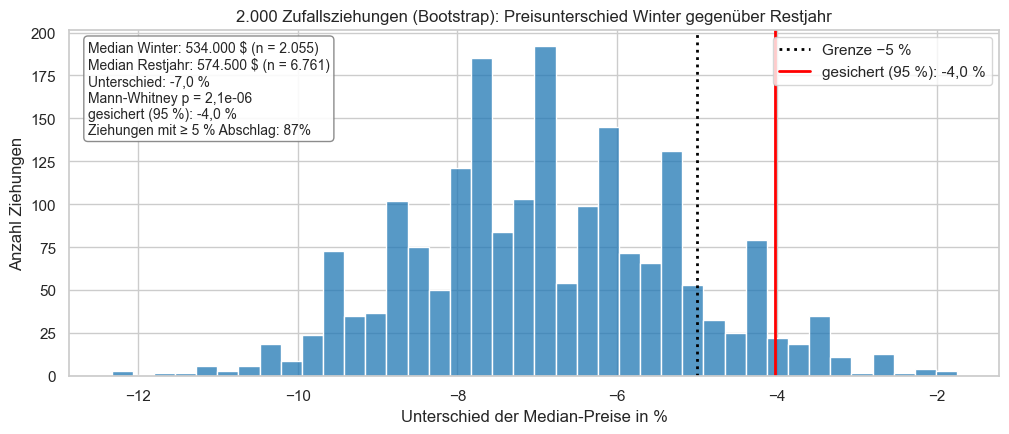

In [9]:
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.histplot(boot, bins=40, ax=ax, color="tab:blue")
ax.axvline(-5, color="black", ls=":", lw=2, label="Grenze −5 %")
ax.axvline(obere_grenze, color="red", lw=2, label=f"gesichert (95 %): {de(obere_grenze, 1)} %")
ax.set_title("2.000 Zufallsziehungen (Bootstrap): Preisunterschied Winter gegenüber Restjahr")
ax.set_xlabel("Unterschied der Median-Preise in %")
ax.set_ylabel("Anzahl Ziehungen")
ax.legend(loc="upper right")
kennzahlen(ax, f"Median Winter: {de(winter.median())} $ (n = {de(len(winter))})\n"
               f"Median Restjahr: {de(rest.median())} $ (n = {de(len(rest))})\n"
               f"Unterschied: {de(diff, 1)} %\n"
               f"Mann-Whitney p = {p_de(p_wert)}\n"
               f"gesichert (95 %): {de(obere_grenze, 1)} %\n"
               f"Ziehungen mit ≥ 5 % Abschlag: {anteil_5:.0%}",
           x=0.02, ha="left")
plt.show()

**Kennzahlen**

| Kennzahl | Wert |
|---|---|
| Median Winter (n = 2.055) | 534.000 $ |
| Median Restjahr (n = 6.761) | 574.500 $ |
| Unterschied | −7,0 % |
| Mann-Whitney-U p-Wert | 2,1 · 10⁻⁶ (signifikant) |
| Mit 95 % Sicherheit mindestens | −4,0 % |
| Ziehungen mit mind. 5 % Abschlag | 87 % (nötig: 95 %) |

**Was bedeutet das?**
- Große Häuser sind im Winter **wirklich günstiger**, der p-Wert liegt weit unter 0,05. Im Median sind es rund **7 %**.
- Die rote Linie liegt aber **rechts** von der −5-%-Linie. Mit 95 % Sicherheit können wir nur **etwa 4 %** belegen. Ungefähr jede achte Ziehung zeigt weniger als 5 % Abschlag.
- **Ergebnis: H1 ist nicht bestätigt.** Die Richtung stimmt, aber die 5 % sind statistisch nicht abgesichert.

---
## 6. Folgefrage: Liegt es an der Jahreszeit oder an der Lage?
Vielleicht wurden im Winter einfach **kleinere Häuser** oder Häuser in **günstigeren Gegenden** verkauft? Dann wäre der „Winterrabatt“ gar kein echter Jahreszeiten-Effekt.

**Methode:** Wir machen den Vergleich Schritt für Schritt fairer:
- **Preis pro qm** statt Gesamtpreis → die Hausgröße ist herausgerechnet.
- **Preis pro qm innerhalb derselben Postleitzahl** → zusätzlich ist die Lage herausgerechnet. Dafür nehmen wir nur PLZ mit mindestens 10 Verkäufen pro Jahreszeit, berechnen dort den Unterschied und nehmen davon den Median.

                    Wohnfläche (qm)  Bauqualität  Schlafzimmer
saison                                                        
Restjahr (Mär–Okt)           233.19         8.00          4.00
Winter (Nov–Feb)             232.26         8.00          4.00 

Gesamtpreis                          -7.00
Preis pro qm                         -4.60
Preis pro qm, gleiche PLZ (63 PLZ)   -1.10
dtype: float64


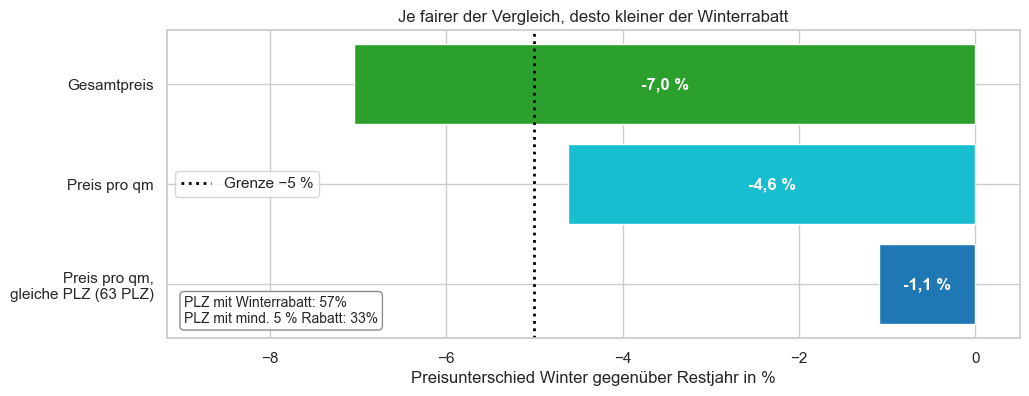

In [10]:
# Unterscheiden sich die Häuser selbst?
print(gross.groupby("saison")[["qm_living", "grade", "bedrooms"]].median()
      .rename(columns={"qm_living": "Wohnfläche (qm)", "grade": "Bauqualität", "bedrooms": "Schlafzimmer"}), "\n")

# 1) Preis pro qm
qm_w = gross.loc[gross["winter"], "preis_pro_qm_wohnflaeche"].median()
qm_r = gross.loc[~gross["winter"], "preis_pro_qm_wohnflaeche"].median()
diff_qm = 100 * (qm_w / qm_r - 1)

# 2) Preis pro qm innerhalb derselben PLZ
plz = gross.groupby(["zipcode", "winter"])["preis_pro_qm_wohnflaeche"].agg(["median", "size"]).unstack()
plz = plz[(plz["size"] >= 10).all(axis=1)]
plz_diff = 100 * (plz["median"][True] / plz["median"][False] - 1)
diff_plz = plz_diff.median()

stufen = pd.Series({"Gesamtpreis": diff, "Preis pro qm": diff_qm,
                    f"Preis pro qm,\ngleiche PLZ ({len(plz_diff)} PLZ)": diff_plz})
print(stufen.rename(lambda s: s.replace("\n", " ")).round(1))

fig, ax = plt.subplots(figsize=(11, 4))
ax.barh(stufen.index[::-1], stufen.values[::-1], color=["tab:blue", "tab:cyan", "tab:green"])
ax.axvline(-5, color="black", ls=":", lw=2, label="Grenze −5 %")
for i, v in enumerate(stufen.values[::-1]):
    ax.text(v / 2, i, f"{de(v, 1)} %", va="center", ha="center", color="white", weight="bold")
ax.set_xlim(stufen.min() * 1.3, 0.5)
ax.set_xlabel("Preisunterschied Winter gegenüber Restjahr in %")
ax.set_title("Je fairer der Vergleich, desto kleiner der Winterrabatt")
ax.legend(loc="center left")
kennzahlen(ax, f"PLZ mit Winterrabatt: {(plz_diff < 0).mean():.0%}\n"
               f"PLZ mit mind. 5 % Rabatt: {(plz_diff <= -5).mean():.0%}",
           x=0.02, y=0.04, ha="left", va="bottom")
plt.show()

**Kennzahlen:** Median-Wohnfläche Winter 232 qm, Restjahr 233 qm (Bauqualität und Schlafzimmer gleich) · Gesamtpreis −7,0 % · Preis pro qm −4,6 % · Preis pro qm in gleicher PLZ −1,1 % (63 PLZ) · nur in 57 % der PLZ ist der Winter überhaupt günstiger, in 33 % um mind. 5 %

**Was bedeutet das?** Die Häuser selbst unterscheiden sich kaum (gleiche Wohnfläche, gleiche Bauqualität). Rechnet man aber Größe und Lage heraus, **schrumpft der Rabatt von 7 % auf nur noch etwa 1 %**. Innerhalb einer PLZ ist der Winter nur in gut der Hälfte der Fälle günstiger, das ist kaum mehr als ein Münzwurf. Ein großer Teil des „Winterrabatts“ entsteht also dadurch, dass im Winter anteilig mehr Häuser in **günstigeren Gegenden** verkauft wurden. Die Jahreszeit selbst spielt nur eine kleine Rolle.

---
## 7. Preis-Jahresuhr
Zum Schluss fassen wir das Ergebnis in einer Grafik für die Präsentation zusammen. Jeder Monat ist eine Stunde auf der Uhr. Der Abstand zur Mitte zeigt den Median-Preis als **Index (Restjahr = 100)**. Der gepunktete Ring bei **95** ist die 5-%-Grenze der Hypothese. Mit der Maus sieht man Preis und Anzahl Verkäufe. Die Grafik wird auch als HTML in `output/` gespeichert.

In [11]:
uhr = gross.groupby("monat")["price"].agg(["median", "size"]).reset_index()
uhr["index"] = 100 * uhr["median"] / median_rest
uhr["name"] = [MONATE[m - 1] for m in uhr["monat"]]
uhr = pd.concat([uhr, uhr.iloc[[0]]])  # Kreis schließen

fig = go.Figure()
fig.add_trace(go.Scatterpolar(r=[100] * 13, theta=uhr["name"], mode="lines", name="Restjahr = 100",
                              line=dict(color="#eb6834", dash="dash")))
fig.add_trace(go.Scatterpolar(r=[95] * 13, theta=uhr["name"], mode="lines", name="−5 % (Hypothese)",
                              line=dict(color="black", dash="dot")))
fig.add_trace(go.Scatterpolar(
    r=uhr["index"], theta=uhr["name"], mode="lines+markers", fill="toself", name="Median-Preis (Index)",
    line=dict(color="#2a78d6", width=3), fillcolor="rgba(42,120,214,0.15)",
    marker=dict(size=12, color=["#2a78d6" if m in [11, 12, 1, 2] else "#eb6834" for m in uhr["monat"]]),
    customdata=np.stack([uhr["median"], uhr["size"]], axis=-1),
    hovertemplate="<b>%{theta}</b><br>Index %{r:.1f}<br>Median %{customdata[0]:,.0f} $<br>%{customdata[1]} Verkäufe<extra></extra>",
))
fig.add_annotation(
    x=1.0, y=0.02, xref="paper", yref="paper", xanchor="right", yanchor="bottom", align="left", showarrow=False,
    bgcolor="white", bordercolor="gray", borderwidth=1,
    text=(f"<b>Kennzahlen</b><br>Median Winter: {de(winter.median())} $<br>Median Restjahr: {de(rest.median())} $<br>"
          f"Unterschied: {de(diff, 1)} % (p = {p_de(p_wert)})<br>gesichert (95 %): {de(obere_grenze, 1)} %<br>"
          f"gleiche Größe und PLZ: {de(diff_plz, 1)} %<br><b>H1 nicht bestätigt</b>"),
)
fig.update_layout(
    title="Preis-Jahresuhr: Häuser mit mind. 4 Schlafzimmern (blau = Winter)",
    polar=dict(radialaxis=dict(range=[85, 108]), angularaxis=dict(direction="clockwise", rotation=90)),
    height=650, template="plotly_white", separators=",.",
)
fig.write_html("output/h1_jahresuhr_c.html")
fig.show()

**Was sehen wir?** Die Uhr ist im Winter (November bis Februar) nach innen „eingedellt“. Alle vier Wintermonate liegen am oder innerhalb des 95er-Rings, der Februar am tiefsten. Im Frühling (März bis Juli) sind die Preise am höchsten. Die Delle ist sichtbar, aber nicht groß. Das passt zum Testergebnis: Es gibt einen Winterrabatt, aber die 5 % sind nicht gesichert.

---
## 8. Fazit

| | |
|---|---|
| Hypothese | Große Häuser (mind. 4 Schlafzimmer) sind im Winter mind. 5 % günstiger |
| Gemessen | −7,0 % im Median, signifikant (Mann-Whitney p = 2,1 · 10⁻⁶) |
| Mit 95 % Sicherheit | nur ca. −4 % |
| Bei gleicher Größe und Lage | nur noch ca. −1 % |
| **Ergebnis** | **H1 nicht bestätigt**: Die Richtung stimmt, die Höhe nicht. |

**Erkenntnisse**
1. Im Winter werden weniger große Häuser verkauft, und sie sind im Median rund 7 % günstiger.
2. Statistisch gesichert sind aber nur etwa 4 %, also weniger als die 5 % aus der Hypothese.
3. Der größte Teil des Rabatts kommt von der Lage: Vergleicht man gleich große Häuser in derselben PLZ, bleibt nur etwa 1 % übrig.

**Empfehlungen für Thomas**
1. Mit wenig Rabatt rechnen: Der Winter bringt eher 1–4 % (ca. 6.000–23.000 $). Das ist ein netter Puffer, aber nichts, womit man fest planen sollte.
2. Wenn Winter, dann Januar/Februar: Im Herbst suchen und die Finanzierung klären, Anfang des Jahres kaufen. Ab März ist der Vorteil weg.
3. Die Lage ist der größere Hebel: Wer bei der Postleitzahl flexibel ist, spart deutlich mehr als mit dem richtigen Zeitpunkt (siehe Hypothese 2).

**Grenzen:** Nur ein Winter (2014/15) im Datensatz · `date` ist das Abschlussdatum, nicht der Zeitpunkt der Verhandlung · Markt von 2014/15, nicht direkt auf heute übertragbar.